# Quantum Metal flip-chip tutorial — a crossmon on the qubit chip over a λ/4 on the control chip (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial `docs/tut/2-From-components-to-chip/FlipChip-design-tutorial.ipynb`
(© IBM / Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/flipchip_qubit_resonator.md`): a `DesignFlipChip` with two facing 9 × 9 mm chips 10 µm apart.
The qubit chip `Q_chip` carries a `TransmonCross` (150 µm arms, 20 µm wide, 20 µm gap, one claw); the control chip
`C_chip` below it a `ReadoutResFC`, a CPW resonator whose open end is a 20 µm-radius disk **directly under the
cross's centre**: the qubit couples to the resonator vertically, across the chip gap. No routes, launchpads or bumps.
The tutorial then runs an HFSS eigenmode + EPR analysis (2 modes, Lj 10 nH). We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): both
components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the faces, the stack, the
junction, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chips | two 9 × 9 mm chips centred on (0, 0), 10 µm vacuum gap | KQC faces: the control chip is face `1t1` (bottom chip, top face), the qubit chip face `2b1` (top chip, bottom face), on the 7.5 mm Quantcore die |
| frame | none | the QCT frame on face 1t1; face 2b1 has none (PDK v3 defines no frame for the flip-chip top chip; its fab layers are 800–804/0) |
| substrate | custom silicon, εr 11.45 (FEM setting) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| junction | Metal junction line, `hfss_inductance` 10 nH | Quantcore trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); on face 2b1 its fingers export to 803/0 + 804/0 |
| pads | none | none (nothing for the pad rule to place) |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| coupling | geometric, solved by HFSS | declared: the parallel plate between the disk and the cross centre across the 10 µm gap (rough) |
| placement | both chips centred on the pair's origin | the pair's content centred in the die |

**Kept exactly:** both components with the tutorial's options and their relative position (the disk under the
cross centre); Q1 is drawn in the same global (x, y) as R1, on face 2b1 (`face_ids = ["2b1", "1t1", "2t1"]`); both
faces keep their ground plane, as in the source.

**Substituted / added:**
1. The resonator's far end (`readout`) has no route: the trace runs into the ground plane there (Metal draws it so,
   and the tutorial's HFSS model shorts it). The `ReadoutResFC` LOM model makes a free `readout` an open end, so a
   `metal:ShortToGround` (it draws nothing) is snapped onto that pin to make the LOM's line the drawn λ/4.
2. The vertical coupling is not a route: it is declared (`Cg_Q1_R1`) as the parallel plate between the disk and the
   cross centre above it across the 10 µm vacuum gap (1131 µm² overlap → 1.0 fF; rough, fringing ignored).
3. The chip gap (10 µm) and the custom silicon are FEM settings in the source, not layout: the LOM uses the PDK
   substrate. There is no FEM job yet (Simulate 1: the exporter has no two-face stack).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the crossmon on the top chip, the resonator on the bottom chip with its shorted
end, the vertical coupling between them, and then the whole chip (no pads, feedline or routes: segments 2, 3 and 7
say so in one sentence). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `flipchip_qubit_resonator.v1.ipynb`; both save the same
`flipchip_qubit_resonator.json`.

## Setup

The imports, the output folder, the face selector `TOP` and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
TOP = {"face_ids": ["2b1", "1t1", "2t1"]}        # Q_chip: the top chip's bottom face

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame on the control chip's face 1t1; there are no pads; Q1 gets the PDK nominal trilayer junction (drawn on face 2b1); the free ground of face 1t1 gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). Here nothing is routed: the qubit and the resonator talk across the gap between the two chips, so the
segments are the two components and the coupling that joins them.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 mm die with the QCT frame (on the control chip's face 1t1) |
| 2–3 | nothing: no bond pads and no feedline (a simulation example) |
| 4 | the crossmon on the qubit chip (face 2b1), with its trilayer junction |
| 5 | the readout: the λ/4 `ReadoutResFC` on the control chip and its shorted end |
| 6 | the coupling: the declared vertical capacitance across the 10 µm chip gap |
| 7 | nothing: no control lines |
| 8 | the whole chip: centring, save (no sim group yet) |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
source's 9 × 9 mm chips hold only the ≈ 1 mm qubit / resonator pair, so the rebuild uses the 7.5 mm Quantcore die
centred on them (`box=(750, 750, 8250, 8250)`). Metal centres both chips on (0, 0), so a Metal position (x, y) is
`P(x, y)` = (4500 + x, 4500 + y) here, on both faces.

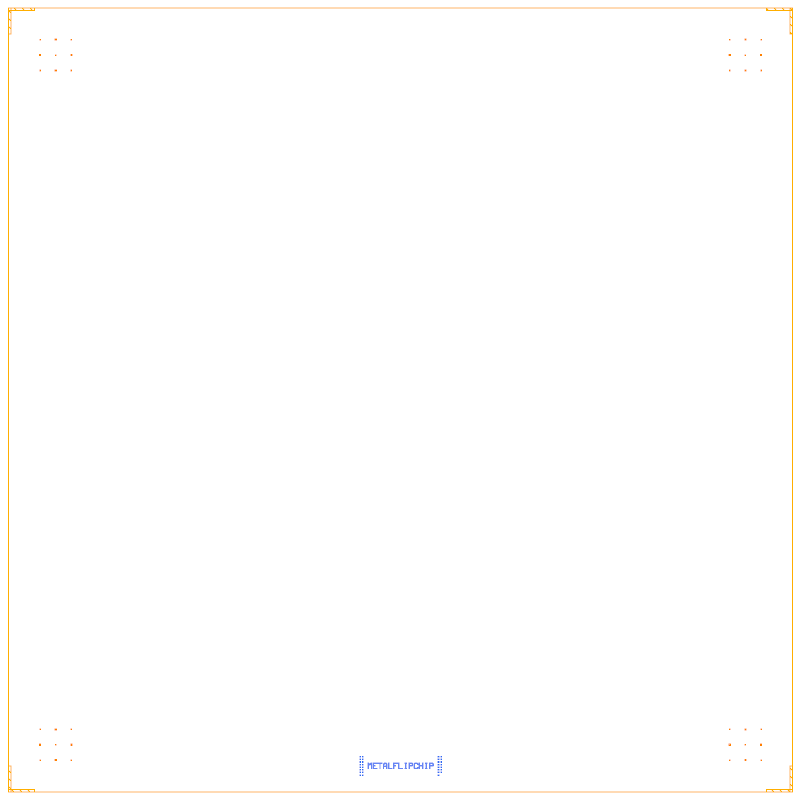

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_s1_die.png')

In [5]:
d = Designer("flipchip_qubit_resonator", box=(750, 750, 8250, 8250), chip={"name_chip": "MetalFlipChip"},
             live=LIVE)
P = lambda x, y: (4500 + x, 4500 + y)            # Metal µm → Designer µm (both 9 × 9 mm chips centred on (0, 0))
layout_step(d, OUT / "flipchip_qubit_resonator_s1_die.png", size=(800, 800), width=320)

## Design 2 · Bond pads

The tutorial has **no launchpads**: the pair is a simulation example, read out in HFSS, so the PDK pad rule (outer
etch of every bond pad 100 µm from the die edge) has nothing to place here; `pads_md` in Design 8 confirms it.

## Design 3 · Readout: the line

No feedline either: the resonator (segment 5) is the whole readout, with no port on the chip.

## Design 4 · Qubit placement: the crossmon on the top chip

**The qubit.** `metal:TransmonCross` with the tutorial's options (150 µm arms, 20 µm wide, 20 µm gap) and one claw
`claw_west` (30 µm, the source's `connection_pads`). `TOP` puts it on face **2b1**, the qubit chip's face that looks
down at the control chip: it is drawn in the same global (x, y) as Metal places it. Its junction is the PDK nominal
trilayer junction (`trilayer_junction`: fingers 0.5 × 0.6 µm, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); `junction=` carries
L_J and C_J to the LOM. On face 2b1 the fingers export to the face-2b1 junction layers 803/0 + 804/0.

**The claw vs the arm (PDK `pdk_claw`).** A `TransmonCross` claw longer than the arm reach (arm + ground spacing −
half the arm width = 145 µm here) runs into the side arms' gap; the fix is a longer `cross_length`. The 30 µm
claw is far inside it (zoom in Fab 2).

The picture frames the area where the resonator will run (segment 5): for now only the cross on face 2b1.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


Q1 ports: ['claw_west', 'squid_a', 'squid_b']


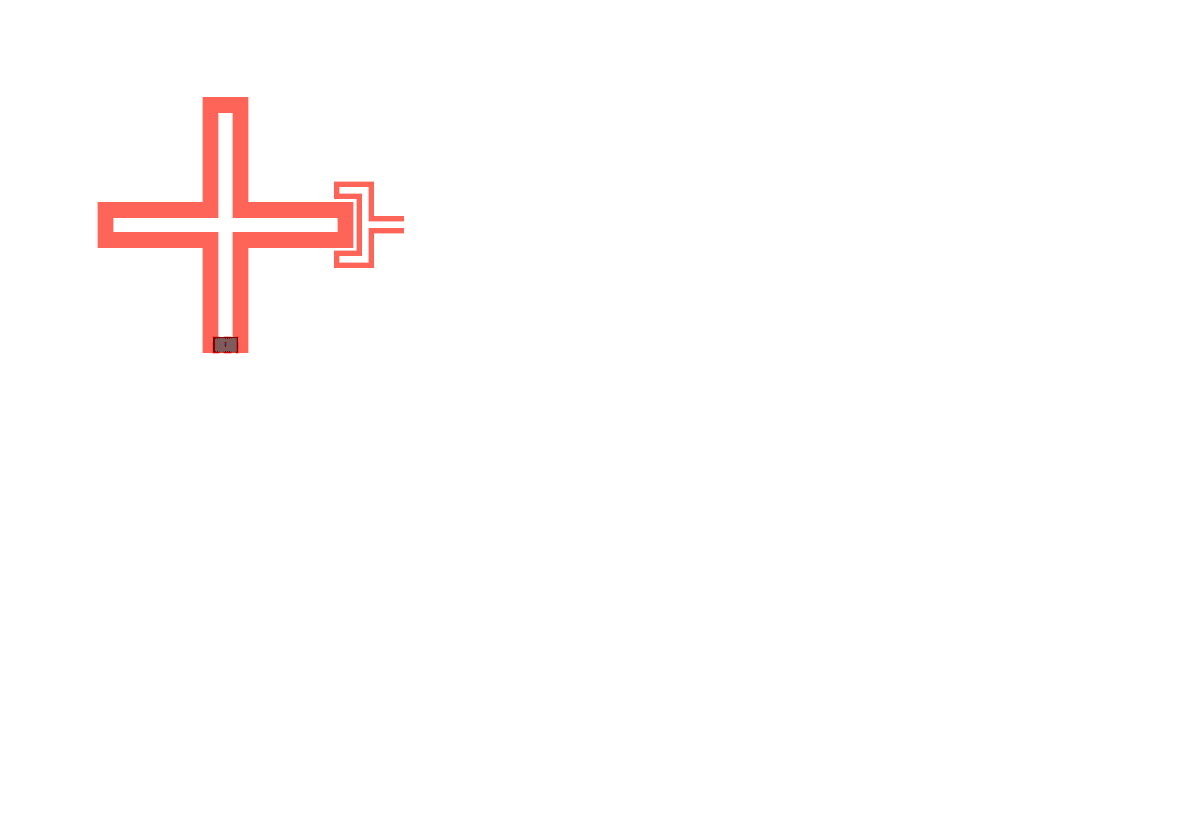

**On the chip so far:** 0 pads · 1 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `Q1`.

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_s4_qubit.png')

In [6]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    claw = dict(connector_type="0", claw_length="30um", ground_spacing="5um", claw_width="10um", claw_gap="6um")
    q1 = d.add("Q1", "metal:TransmonCross", at=P(0, 0), junction=JUNCTION, **JJ_PARAMS, **TOP, cross_width="20um",
               cross_length="150um", cross_gap="20um", connection_pads={"claw_west": {"connector_location": "180", **claw}})
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / "flipchip_qubit_resonator_s4_qubit.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825),
            width=480)

## Design 5 · Readout: the resonator on the bottom chip and its shorted end

**The resonator.** `metal:ReadoutResFC` on face 1t1 (the default face): its CPW (10 µm trace, 10 µm gap, 50 µm turn
radius, five sections `readout_l1…l5`) starts at a 20 µm-radius disk under the cross centre.

- `R1_end`: a `metal:ShortToGround` snapped onto the resonator's `readout` pin (it draws nothing). The drawn trace
  runs into the ground plane there, and the tutorial's HFSS model shorts it: with the short, the LOM's line is the
  drawn λ/4.

R1 ports: ['readout']


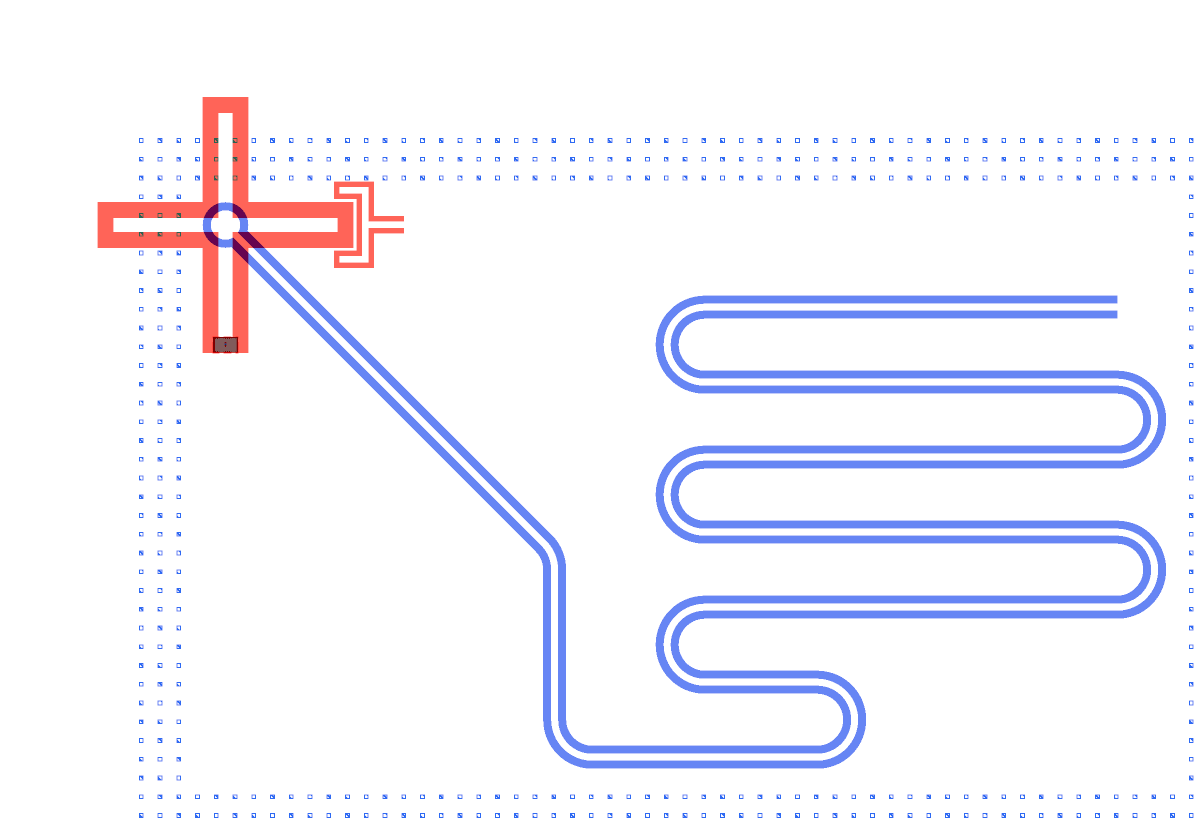

**On the chip so far:** 0 pads · 1 qubits · 2 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `R1`, `R1_end`.

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_step_parts.png')

In [7]:
with d.batch():
    r1 = d.add("R1", "metal:ReadoutResFC", at=P(0, 0), readout_radius="20 um", readout_cpw_width="10 um",
               readout_cpw_gap="10 um", readout_cpw_turnradius="50 um", readout_l1="600 um", readout_l2="200 um",
               readout_l3="300 um", readout_l4="150 um", readout_l5="550 um", arc_step="5 um")
    d.add("R1_end", "metal:ShortToGround", snap="short", to="R1.readout")   # the drawn shorted end, for the LOM
print("R1 ports:", sorted(r1.ports))
layout_step(d, OUT / "flipchip_qubit_resonator_step_parts.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825),
            width=480)

## Design 6 · Coupling: the vertical capacitance across the chip gap

The source has **no routes**: the qubit and the resonator talk across the chip gap. The coupling is declared:

- `Cg_Q1_R1`: the vertical coupling, declared with `d.couple`. The disk (r = 20 µm) lies under the cross centre (two
  crossing 20 µm strips), so the overlap is the disk minus the four corner caps beyond |x|, |y| > 10 µm; ε0·A/d
  across the 10 µm vacuum gap gives the capacitance (rough: fringing ignored, which would raise it).

The picture zooms on the disk under the cross centre (the overlap that makes the capacitance).

overlap 1131 µm² → C_vertical 1.0 fF (parallel plate, rough)


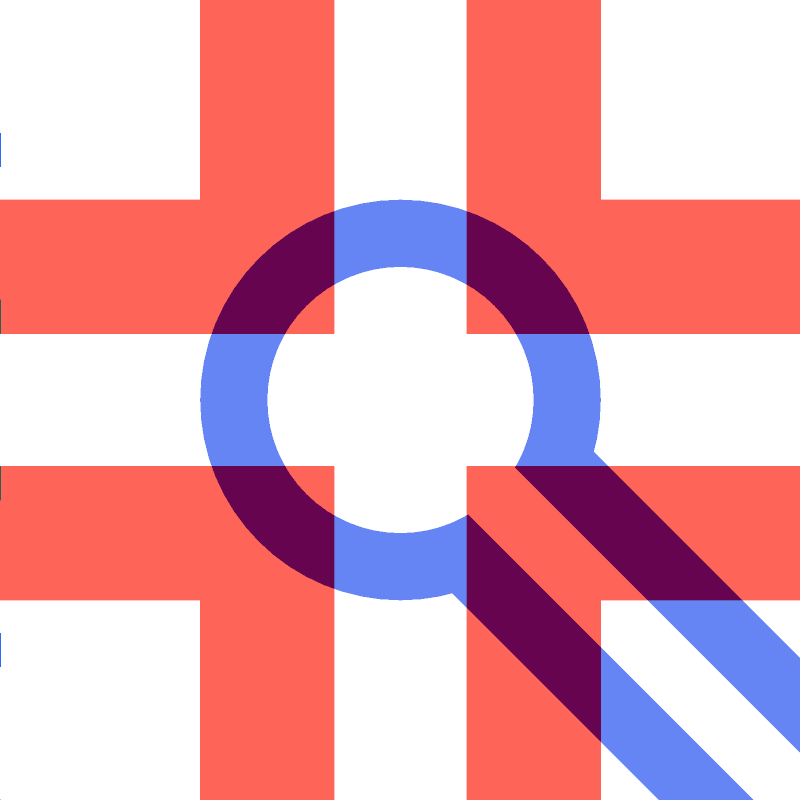

**On the chip so far:** 0 pads · 1 qubits · 2 other components · 0 routes · 1 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_s6_coupling.png')

In [8]:
r, h = 20.0, 10.0                                # disk radius, half the cross strip width (µm)
cap = (lambda F: F(math.sqrt(r * r - h * h)) - F(h))(lambda x: x / 2 * math.sqrt(r * r - x * x) + r * r / 2 * math.asin(x / r)) \
      - h * (math.sqrt(r * r - h * h) - h)
A = math.pi * r * r - 4 * cap                    # disk ∩ cross centre (µm²)
GAP = 10.0                                       # the tutorial's chip gap (µm, vacuum)
C_V = round(8.854e-3 * A / GAP, 2)               # ε0 A / d in fF (ε0 = 8.854e-3 fF/µm)
print(f"overlap {A:.0f} µm² → C_vertical {C_V} fF (parallel plate, rough)")
with d.batch():
    d.couple("Cg_Q1_R1", "Q1", "R1.res", C_fF=C_V, note="disk under the cross centre, 10 µm vacuum gap (rough)")
layout_step(d, OUT / "flipchip_qubit_resonator_s6_coupling.png", box=P(-60, -60) + P(60, 60), size=(800, 800),
            width=320)

## Design 7 · Routing: control lines

None: the tutorial drives and reads the pair only in HFSS.

## Design 8 · The whole chip: centring, save

**No sim group.** The FEM exporter builds face 1t1 only, so a group of Q1 + R1 would leave the qubit out of the
solver model (Simulate 1); the design has none until the exporter builds a two-face stack.

**Centring.** The PDK wants the chip content centred in the die. Metal centres both chips on the qubit, so the pair (the cross and
the resonator that runs 1.2 mm east and 0.7 mm south of it) sits off-centre: `center_in_die` shifts the whole design
(both faces together, the disk stays under the cross) so the content's centre is the die centre. `R1_end` is
snapped and follows R1. After the shift `P` is redefined relative to Q1 (Metal's origin), so the pictures below use
the same frames.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*.

content shifted by (-539.4, 274.8) µm


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

**Same design as before:** `examples/designs/metal/flipchip_qubit_resonator.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer flipchip_qubit_resonator: 3 instances, 0 routes, live=False> → examples\designs\metal\flipchip_qubit_resonator.json


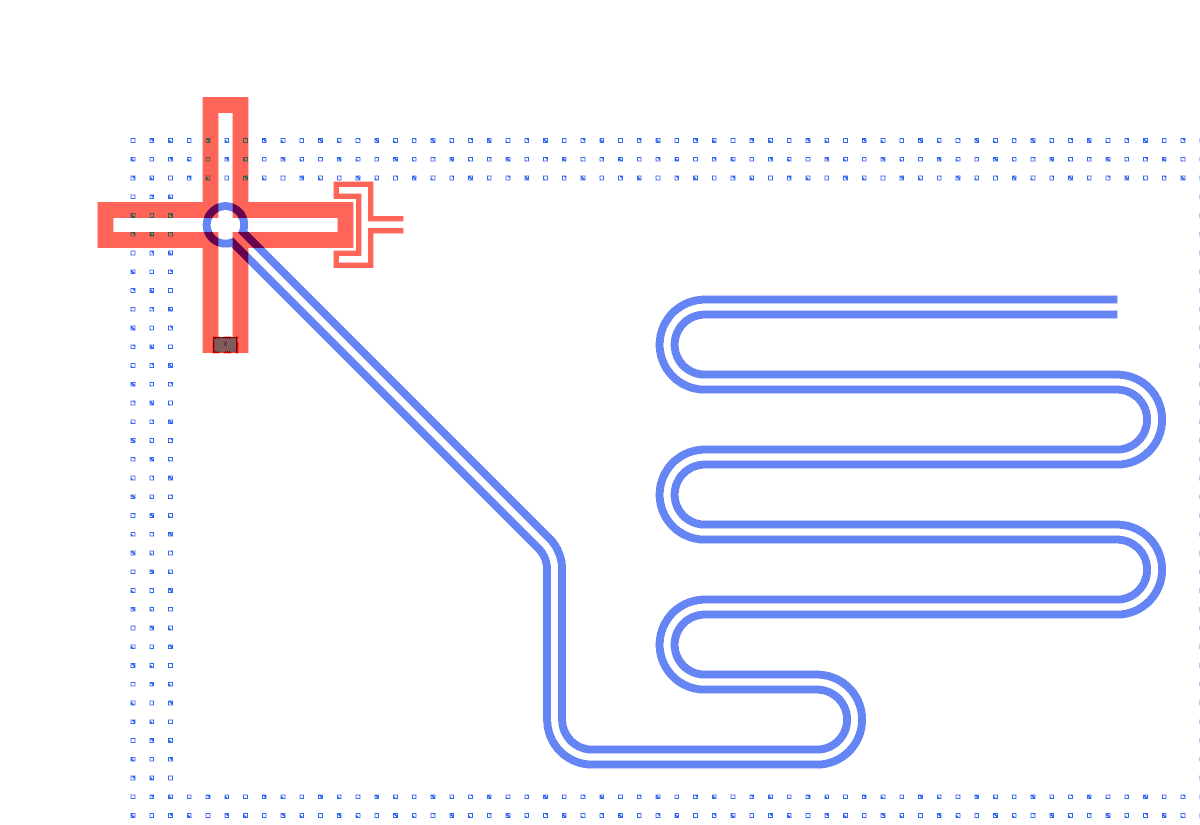

**On the chip so far:** 0 pads · 1 qubits · 2 other components · 0 routes · 1 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_step_routes.png')

In [9]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
P = lambda x, y: (QX + x, QY + y)                # Metal µm → Designer µm after the centring (Q1 is Metal's (0, 0))
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "flipchip_qubit_resonator.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "flipchip_qubit_resonator_step_routes.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825),
            width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; three `dangling_port` warnings (Q1's `claw_west`, an open claw on the qubit
chip as in the source, and the junction attachment points `squid_a` / `squid_b`); one `overlap`, Q1 (face 2b1) over
R1 (face 1t1), which is the point of the design: they are on different chips. **No PDK design warnings**: no pads,
the nominal junction is in the R_n window, no target. `pdk_claw` would flag a claw reaching the side arms (it reads
the option strings with their units here, so the check is valid).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: the `TransmonCross` → a grounded cross island with its junction
and C_Σ, a node for the claw; `ReadoutResFC` → its CPW line from the open disk to `readout`, here shorted by `R1_end`
(a λ/4 `TLres`); the declared vertical `Cg_Q1_R1` joins the island and the resonator's open end. The port map shows
which node each port landed on.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "R1"))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat solves the normal modes, QuTiP the dressed values: f_q, α of Q1 and f_r, χ of R1 (κ is 0: the source has no
port). With the PDK junction (6.73 nH, 15 fF; numbers from the v1 run) the crossmon sits at ≈ 6.5 GHz, just above the ≈ 6.4 GHz λ/4 (the
tutorial's 10 nH put it at 5.78 GHz), so χ comes out positive (the qubit sits between the resonator and
resonator + |α|); the tutorial reports no values, so there is nothing to compare with except the
PDK band (4–8 GHz). χ comes through the rough 1.0 fF vertical coupling.

In [ ]:
res = simulate_groups(d, {"Q1+R1": ["Q1", "R1", "R1_end"]})
display(Markdown(modes_md(res["Q1+R1"]) + "\n\n" + groups_md(res)))

## LOM 2 · The LOM in two plots

The same result as pictures: (a) the two normal modes of `Q1+R1` (QuCat; the circle is the qubit, the square the
resonator; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of the resonator. Here (from
the v1 run) the dressed qubit sits only ≈ 0.14 GHz above the resonator, inside the straddling band
f_r < f_q < f_r + |α|, which is why χ is positive.

In [ ]:
plot_lom(res, OUT / "flipchip_qubit_resonator_lom.png", title="flip chip: LOM of Q1 + R1")

## LOM 3 · One geometry change, by hand

Before any FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here the resonator's first section `readout_l1`, 600 → 500 µm, 100 µm off the λ/4 — rebuild, re-run the LOM and
compare. A shorter λ/4 resonates higher (f ∝ 1/ℓ, ≈ +2 %); the qubit barely moves; χ grows as the resonator moves
towards the qubit.

In [ ]:
d2 = design_copy(DESIGN)
d2["R1"].set(readout_l1="500 um")                # 600 → 500 µm
res2 = simulate_groups(d2, {"Q1+R1": ["Q1", "R1", "R1_end"]})
display(Markdown(params_delta_md(res, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS (nothing to export yet)

The tutorial's analysis is an HFSS eigenmode + EPR of the qubit and the resonator across the 10 µm gap. **qcc cannot
export it yet (open request for sim export):** a sim group of Q1 + R1 exports, but its simulation geometry
is face 1t1 only (`1t1_gap`, `1t1_ground`, one substrate): Q1's metal is on the `2b1_*` layers and never reaches the
solver model, and a C-matrix job finds no nets. The design therefore has **no sim group** until the exporter builds
a two-face stack (KQC `face_stack = ["1t1", "2b1"]` with the chip gap); the vertical coupling stays the LOM's
estimate. The export call below is kept so the notebook exports the group once it exists.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # every sim group of the design: none yet
print(len(jobs), "FEM jobs")

## Simulate 2 · Component simulation

No job: the design has no sim group (Simulate 1). The C-matrix of the pair would replace the declared 1.0 fF and the
cross's C_Σ estimate once a two-face export exists.

## Simulate 3 · Eigenmode simulation

No job either: the tutorial's own HFSS eigenmode + EPR of the pair across the 10 µm gap is the one to reproduce, and
it needs the two-face stack.

## Simulate 4 · Full-wave (driven) run

Nothing to drive: the chip has no port (no pad, no feedline).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step. Without a FEM job (Simulate) there is nothing to plot, read or compare yet:
**Results 1–3** (the eigenmode plots, their values, FEM against the LOM) stay empty for this chip until the exporter
builds a two-face stack. The feedback and the iteration run on the LOM.

## Results 4 · Feedback: one step towards a target

The tutorial states no targets, and in the LOM the qubit sits in the straddling band just above its resonator (LOM 2).
This notebook sets one target as an exercise that moves it out: **Q1 at 6.85 GHz**, ≈ 0.3 GHz above where the LOM
puts it (from the v1 run: 6.54 GHz), above f_r + |α| ≈ 6.67 GHz. It is reachable inside the PDK junction window: by
the transmon formula L_J goes from 6.73 nH to ≈ 6.2 nH, R_n ≈ 41 kΩ (`pdk_lj_bounds` keeps the feedback within
40–50 kΩ). The resonator is not targeted: its five sections (`readout_l1` …) are not a resonator-length knob the
feedback knows, so it moves L_J only (the proposal's notes list what it left out).

The targets go on a copy (`target_copy` → `build/flipchip_qubit_resonator_target.json`), so the design file keeps its
own (none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on the qubit–readout pair of
the circuit (the cross with the λ/4 it reaches through the declared `Cg_Q1_R1`) and picks one value per quantity (the
consensus); there is no FEM point. `loop.feedback` anchors a surrogate on that point and proposes the knobs that put
the target inside its tolerance (f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The
revision changes the LOM's L_J; to draw the new junction, size its fingers with `trilayer_junction(..., lj_nH=...)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 6.85}}              # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
an0 = loop.analyse(str(DESIGN_T), None, readout=False)   # no FEM job: the LOM estimates
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until the
target is inside its tolerance or `MAX_ITER` revisions are made (`build/flipchip_qubit_resonator/revisions/`). With no
FEM job every revision is judged on the LOM (`RUN_FEM` changes nothing here). The table shows each iteration's value
against the target and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
history, last, an_last = iterate_to_target(DESIGN_T, None, max_iter=MAX_ITER, bounds=BOUNDS, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "flipchip_qubit_resonator_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The flip-chip tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer of face 1t1 (5 µm squares, 20 µm
gaps, three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). The qubit's face 2b1
exports to 800–804/0 (no frame and no cheese band there).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

Both faces (red: the qubit chip's face 2b1, blue: the control chip's face 1t1; compare the tutorial's screenshot);
the cross centre over the resonator's disk (and the 30 µm claw, well inside the arm reach); the resonator's shorted
end; the **fab mask** round the pair (face-1t1 etch with the PDK cheese band, the 3/0 keep-out; face 2b1 on
800–804/0); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read
from the design after the centring shift (`P` is relative to Q1).

In [ ]:
show_snapshot(d, OUT / "flipchip_qubit_resonator.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825))
show_snapshot(d, OUT / "flipchip_qubit_resonator_disk.png", box=P(-60, -60) + P(60, 60), size=(800, 800), width=320)
show_snapshot(d, OUT / "flipchip_qubit_resonator_end.png", box=P(1120, -180) + P(1260, -40), size=(800, 800), width=320)
snap_file(Path("build") / "flipchip_qubit_resonator_fab.oas", OUT / "flipchip_qubit_resonator_cheese.png",
          box=P(-300, -800) + P(1300, 300), size=(1200, 825), width=480)
show_snapshot(d, OUT / "flipchip_qubit_resonator_frame.png", box=(750, 750, 1650, 1650), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | both Metal components and their options, the disk under the cross centre, the two faces (qubit chip over control chip), the shorted resonator end |
| PDK changes | the 7.5 mm die with the QCT frame on face 1t1; sapphire stack; trilayer junction (PDK nominal, on face 2b1 → 803/0 + 804/0); PDK cheese band on face 1t1; content centred (shift (−539, +275) µm in the v1 run) |
| differs | the vertical coupling is a declared parallel-plate estimate (1.0 fF); from the v1 run: f_q 6.54 GHz with the PDK junction (the tutorial's 10 nH gave 5.78 GHz), just above the 6.40 GHz λ/4, so χ is positive (+11.6 MHz, straddling) |
| PDK design warnings | none |
| layout | built in segments (die, the crossmon, the resonator with its shorted end, the vertical coupling, the whole chip; no pads, feedline or routes); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 6.85 GHz, out of the straddling band): `loop.analyse` → `loop.feedback` → revisions until on target, on the LOM |
| open | no FEM job: the exporter has no two-face (flip-chip) stack yet, so Simulate and Results 1–3 stay empty; no PDK frame for the top chip (face 2b1) |